# Stats analysis


### TODO
* Toy - Run each model for 10 times, pick the ones with highest NMI and plot
* Use YY's methods using CluSim - EC
* Replace $R$ with the modularity matrix -$\frac{1}{2m} \left( A_{ij} - \frac{k_i k_j}{2m} \right)$  (beware of the minus sign), and that should overlap with cases with $\tau = 0$
* Run LFR 1k - exact and LFR 5k

In [131]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
import random
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import pandas as pd
pd.options.plotting.backend = 'plotly'
from networkx.algorithms.community import modularity
import networkx as nx
import scipy
import numpy as np
import plotly.express as px 
import plotly.graph_objects as go
from plotly.subplots import make_subplots

sns.set_context('notebook')
sns.set_style("ticks")

SMALL_SIZE = 30
MEDIUM_SIZE = 30
BIGGER_SIZE = 30

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=MEDIUM_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=20)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title


In [5]:
import sys
sys.path.extend(['./', '../'])

from src.clustering import LFRGraph
from src.utils import Paths

## Initial stats

In [4]:
def fix_df():
    results_df.loc[:, 'mu'] = results_df['name'].str.replace('LFR-1000-', '', regex=False).astype(int) / 100
    results_df = results_df.rename(columns={'time_taken': 'running_time'})

    results_df = results_df[['timestamp', 'name', 'mu', 'method', 'trial', 'running_time', 'num_clusters', 'modularity', 'NMI', 'AMI', 
                             'output_cluster_path']]

In [30]:
results_df = pd.read_csv('../results/stats_CL.csv', parse_dates=True)
results_df.columns = [col.strip() for col in results_df.columns]
for col in results_df.columns:
    try:
        results_df.loc[:, col] = results_df[col].str.strip()  # weird whitespace issue
    except Exception as e:
        continue
results_df = results_df.drop_duplicates(subset=results_df.columns[1: ], keep='last')
results_df.head()

,timestamp,name,mu,method,tau,tau_max,trial,running_time,num_clusters,modularity,NMI,AMI,output_cluster_path
0,2022-08-05 14:05:39.040618,LFR-1000-50,0.5,GW-C,0.000000,0.039345,1,1.7331,53,0.4685,0.9929,0.9901,results/LFR-1000-50/GW/LFR-1000-50_GW-C_0.0_1_...
1,2022-08-05 14:05:39.952896,LFR-1000-50,0.5,GW-C,0.019672,0.039345,1,0.8851,53,0.4708,1.0000,1.0000,results/LFR-1000-50/GW/LFR-1000-50_GW-C_0.0196...
2,2022-08-05 14:05:40.877880,LFR-1000-50,0.5,GW-C,0.039345,0.039345,1,0.9013,53,0.4708,1.0000,1.0000,results/LFR-1000-50/GW/LFR-1000-50_GW-C_0.0393...
3,2022-08-05 14:05:42.098178,LFR-1000-50,0.5,GW-C,0.000000,0.039345,2,1.1966,54,0.4696,0.9989,0.9985,results/LFR-1000-50/GW/LFR-1000-50_GW-C_0.0_2_...
4,2022-08-05 14:05:43.011841,LFR-1000-50,0.5,GW-C,0.019672,0.039345,2,0.8891,53,0.4708,1.0000,1.0000,results/LFR-1000-50/GW/LFR-1000-50_GW-C_0.0196...


In [52]:
results_df.loc[:, 'tau_frac'] = (results_df.tau / results_df.tau_max).round(3)
display(results_df.head(2))

display(results_df.tau_frac.value_counts())

,timestamp,name,mu,method,tau,tau_max,trial,running_time,num_clusters,modularity,NMI,AMI,output_cluster_path,tau_frac
0,2022-08-05 14:05:39.040618,LFR-1000-50,0.5,GW-C,0.000000,0.039345,1,1.7331,53,0.4685,0.9929,0.9901,results/LFR-1000-50/GW/LFR-1000-50_GW-C_0.0_1_...,0.0
1,2022-08-05 14:05:39.952896,LFR-1000-50,0.5,GW-C,0.019672,0.039345,1,0.8851,53,0.4708,1.0000,1.0000,results/LFR-1000-50/GW/LFR-1000-50_GW-C_0.0196...,0.5


0.0    1242
0.5     802
1.0     802
Name: tau_frac, dtype: int64

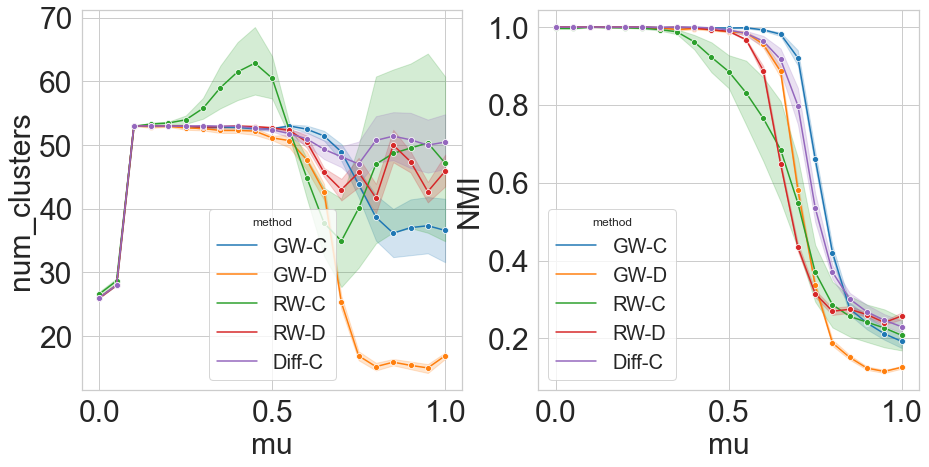

In [32]:
fig, (ax1, ax2) = plt.subplots(figsize=(15, 7), ncols=2, sharex=True)
sns.lineplot(data=results_df, x='mu', y='num_clusters', hue='method', marker='o', ax=ax1);
sns.lineplot(data=results_df, x='mu', y='NMI', hue='method', marker='o', ax=ax2);

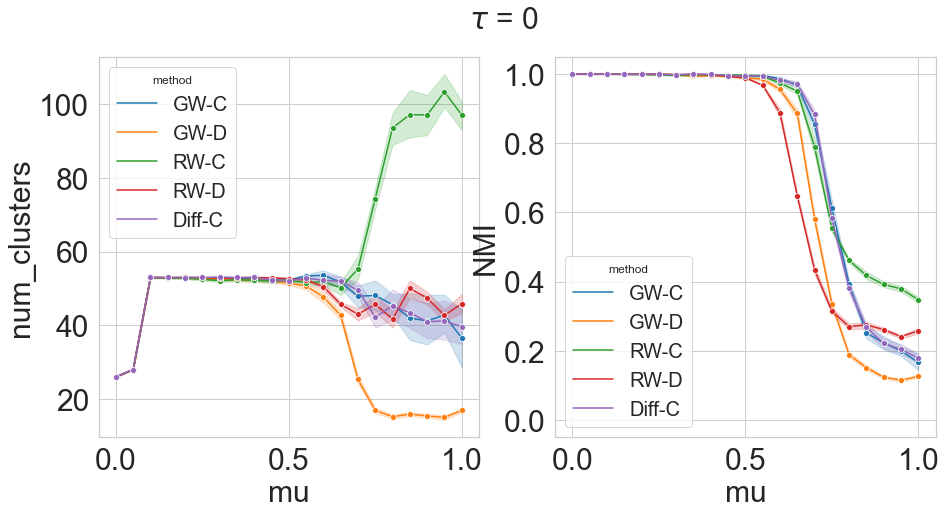

In [33]:
fig, (ax1, ax2) = plt.subplots(figsize=(15, 7), ncols=2, sharex=True)
df = (
    results_df
    .query('tau_frac==0')
)

sns.lineplot(data=df, x='mu', y='num_clusters', hue='method', marker='o', ax=ax1);
sns.lineplot(data=df, x='mu', y='NMI', hue='method', marker='o', ax=ax2);
fig.suptitle(r'$\tau$ = 0')

ax2.set_ylim(-0.05, 1.05);

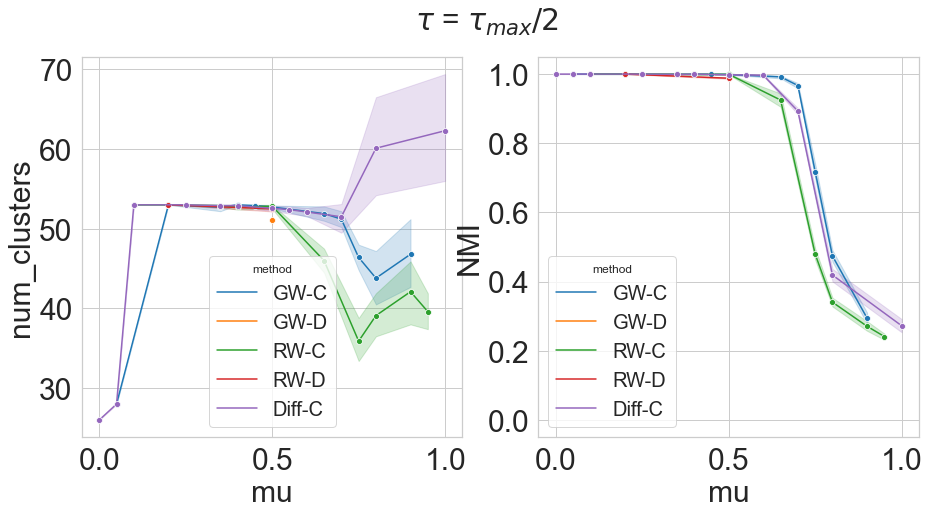

In [36]:
fig, (ax1, ax2) = plt.subplots(figsize=(15, 7), ncols=2, sharex=True)
df = (
    results_df
    .query('tau_frac==0.5')
)

sns.lineplot(data=df, x='mu', y='num_clusters', hue='method', marker='o', ax=ax1);
sns.lineplot(data=df, x='mu', y='NMI', hue='method', marker='o', ax=ax2);
fig.suptitle(r'$\tau$ = $\tau_{max} / 2$')

ax2.set_ylim(-0.05, 1.05);

In [38]:
(
    df
    .query('method=="RW-D"')
)

,timestamp,name,mu,method,tau,tau_max,trial,running_time,num_clusters,modularity,NMI,AMI,output_cluster_path,tau_frac
46,2022-08-05 14:07:09.522355,LFR-1000-50,0.5,RW-D,0.5,1.0,1,1.1675,53,0.4675,0.9902,0.9862,results/LFR-1000-50/RW/LFR-1000-50_RW-D_0.4999...,0.5
49,2022-08-05 14:07:13.331522,LFR-1000-50,0.5,RW-D,0.5,1.0,2,1.4249,53,0.4675,0.9902,0.9862,results/LFR-1000-50/RW/LFR-1000-50_RW-D_0.4999...,0.5
52,2022-08-05 14:07:17.437857,LFR-1000-50,0.5,RW-D,0.5,1.0,3,1.4328,52,0.4671,0.9853,0.9794,results/LFR-1000-50/RW/LFR-1000-50_RW-D_0.4999...,0.5
55,2022-08-05 14:07:21.266240,LFR-1000-50,0.5,RW-D,0.5,1.0,4,1.1496,53,0.4675,0.9902,0.9862,results/LFR-1000-50/RW/LFR-1000-50_RW-D_0.4999...,0.5
58,2022-08-05 14:07:25.379356,LFR-1000-50,0.5,RW-D,0.5,1.0,5,1.1632,52,0.4673,0.9867,0.9813,results/LFR-1000-50/RW/LFR-1000-50_RW-D_0.4999...,0.5
121,2022-08-05 14:18:31.624752,LFR-1000-50,0.5,RW-D,0.5,1.0,1,0.7947,52,0.4674,0.9857,0.9800,results/LFR-1000-50/RW/LFR-1000-50_RW-D_0.4999...,0.5
367,2022-08-05 14:32:36.729936,LFR-1000-20,0.2,RW-D,0.5,1.0,1,0.6190,53,0.7627,1.0000,1.0000,results/LFR-1000-20/RW/LFR-1000-20_RW-D_0.4999...,0.5
370,2022-08-05 14:32:38.651455,LFR-1000-20,0.2,RW-D,0.5,1.0,2,0.6103,53,0.7627,1.0000,1.0000,results/LFR-1000-20/RW/LFR-1000-20_RW-D_0.4999...,0.5
373,2022-08-05 14:32:40.552596,LFR-1000-20,0.2,RW-D,0.5,1.0,3,0.6118,53,0.7627,1.0000,1.0000,results/LFR-1000-20/RW/LFR-1000-20_RW-D_0.4999...,0.5
376,2022-08-05 14:32:42.463102,LFR-1000-20,0.2,RW-D,0.5,1.0,4,0.6104,53,0.7627,1.0000,1.0000,results/LFR-1000-20/RW/LFR-1000-20_RW-D_0.4999...,0.5


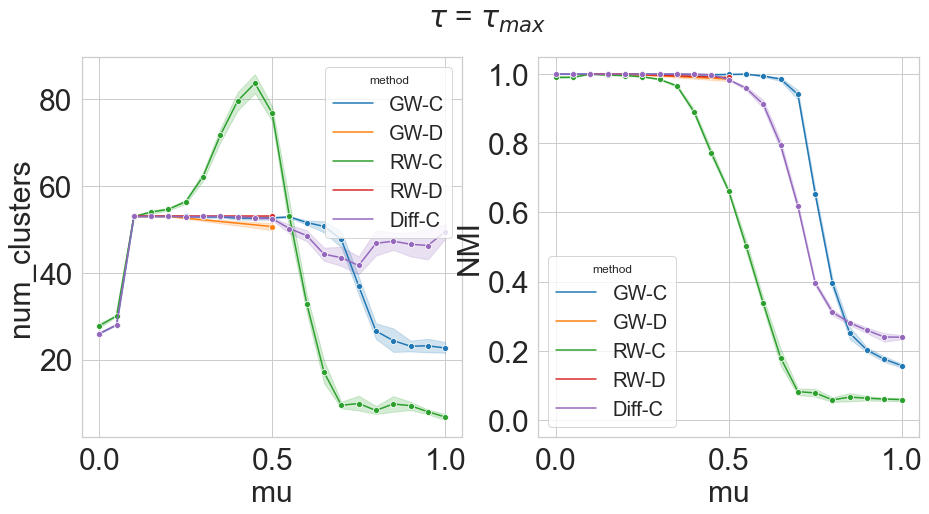

In [39]:
fig, (ax1, ax2) = plt.subplots(figsize=(15, 7), ncols=2, sharex=True)
df = (
    results_df
    .query('tau_frac==1')
)

sns.lineplot(data=df, x='mu', y='num_clusters', hue='method', marker='o', ax=ax1);
sns.lineplot(data=df, x='mu', y='NMI', hue='method', marker='o', ax=ax2);
fig.suptitle(r'$\tau$ = $\tau_{max}$')

ax2.set_ylim(-0.05, 1.05);

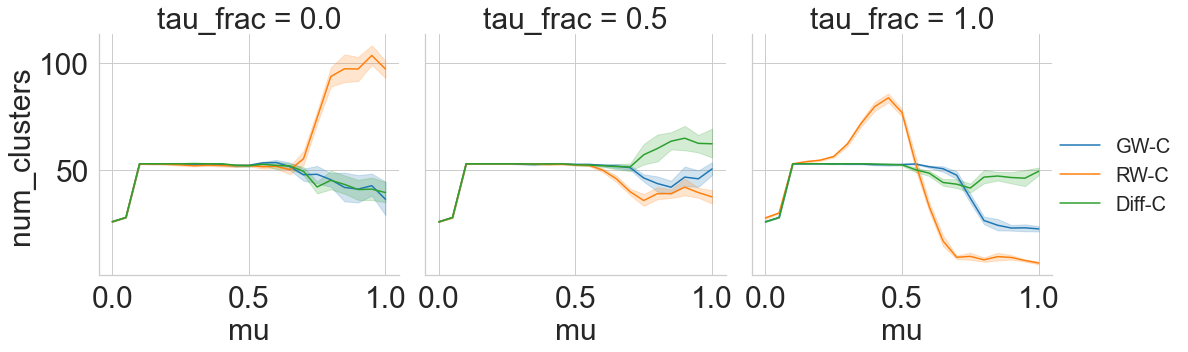

In [54]:
# fig, (ax1, ax2) = plt.subplots(figsize=(15, 7), ncols=2, sharex=True)
df = (
    results_df
    .query('method.str.endswith("-C")', engine='python')
)
fg = sns.FacetGrid(df, col='tau_frac', height=5)
fg.map_dataframe(sns.lineplot, x='mu', y='num_clusters', hue='method')
fg.add_legend()
# sns.lineplot(data=df, x='tau_frac', y='num_clusters', hue='method', marker='o', ax=ax1);
# sns.lineplot(data=df, x='tau_frac', y='NMI', hue='method', marker='o', ax=ax2);
# fig.suptitle(r'$\tau$ = $\tau_{max}$')

# ax2.set_ylim(-0.05, 1.05);

In [ ]:
discard = {'infomap', 'leiden', 'original'}
name = 'LFR-1000-'

df = (
    results_df
    .query('~method.isin(@discard)', engine='python')
    .query('name.str.contains(@name)', engine='python')
)

orig_df = (
    results_df
    .query('method=="original"')
    .query('name.str.contains(@name)', engine='python')
)

fig, axs = plt.subplots(figsize=(30, 20), nrows=2, ncols=2, sharex=True, layout='constrained')
axs = axs.flatten()

for i, (y, ax) in enumerate(zip(['num_clusters', 'modularity', 'NMI', 'AMI'], axs)):
    ax.grid('on')
    if i != 0:
        ax.set_ylim(-0.1, 1.1)
    # Hide the right and top spines
    ax.spines.right.set_visible(False)
    ax.spines.top.set_visible(False)

    # Only show ticks on the left and bottom spines
    ax.yaxis.set_ticks_position('left')
    ax.xaxis.set_ticks_position('bottom')
    
    sns.lineplot(data=orig_df, x='mu', y=y, color='black', linewidth=2, marker='^', markersize=15, label='reference', ax=ax);
    sns.lineplot(data=df, x='mu', y=y, hue='method', ax=ax, marker='o', markersize=13, alpha=0.7);
    ax.set_title(f'{y}');
    ax.set_xlabel(r'$\mu$')
    
    if i != 0:
        ax.legend().set_visible(False)
        
fig.suptitle('LFR 1k nodes, 10 runs each');
# plt.savefig('../results/plots/LFR-1k.png', bbox_inches='tight', dpi=400)

## deeper dive into Correlation clustering

In [ ]:
# results_df = pd.read_csv('../results/stats.csv', parse_dates=True)
# results_df.columns = [col.strip() for col in results_df.columns]
# results_df = results_df.drop_duplicates(subset=results_df.columns[1: ])

# for col in results_df.columns:
#     try:
#         results_df.loc[:, col] = results_df[col].str.strip()  # weird whitespace issue
#     except Exception as e:
#         continue

# display(results_df.head(2))

corr_clust_df = (
    results_df
    .query('~tau.isna()', engine='python')
)

display(corr_clust_df.head(2))

In [ ]:
name = 'LFR-1000-'

df = (
    corr_clust_df
    .query('tau==0')
    .query('name.str.contains(@name)', engine='python')
)

fig, axs = plt.subplots(figsize=(30, 20), nrows=2, ncols=2, sharex=True, layout='constrained')
axs = axs.flatten()

for i, (y, ax) in enumerate(zip(['num_clusters', 'modularity', 'NMI', 'AMI'], axs)):
    ax.grid('on')
    if i != 0:
        ax.set_ylim(-0.1, 1.1)
    # Hide the right and top spines
    ax.spines.right.set_visible(False)
    ax.spines.top.set_visible(False)

    # Only show ticks on the left and bottom spines
    ax.yaxis.set_ticks_position('left')
    ax.xaxis.set_ticks_position('bottom')
    
    sns.lineplot(data=orig_df, x='mu', y=y, color='black', linewidth=2, marker='^', markersize=15, label='reference', ax=ax);
    sns.lineplot(data=df, x='mu', y=y, hue='method', ax=ax, marker='o', markersize=13, alpha=0.7);
    ax.set_title(f'{y}');
    ax.set_xlabel(r'$\mu$')
    
    if i != 0:
        ax.legend().set_visible(False)
        
fig.suptitle(r'LFR 1k nodes, 10 runs each, correlation methods $\tau = 0$');
# plt.savefig('../results/plots/LFR-1k.png', bbox_inches='tight', dpi=400)

In [ ]:
df = (
    corr_clust_df
    .query('name.str.contains(@name)', engine='python')
    .drop_duplicates(subset=['name', 'mu', 'method', 'trial'], keep='last')
)


fig, axs = plt.subplots(figsize=(30, 20), nrows=2, ncols=2, sharex=True, layout='constrained')
axs = axs.flatten()

for i, (y, ax) in enumerate(zip(['num_clusters', 'modularity', 'NMI', 'AMI'], axs)):
    ax.grid('on')
    if i != 0:
        ax.set_ylim(-0.1, 1.1)
    # Hide the right and top spines
    ax.spines.right.set_visible(False)
    ax.spines.top.set_visible(False)

    # Only show ticks on the left and bottom spines
    ax.yaxis.set_ticks_position('left')
    ax.xaxis.set_ticks_position('bottom')
    
    sns.lineplot(data=orig_df, x='mu', y=y, color='black', linewidth=2, marker='^', markersize=15, label='reference', ax=ax);
    sns.lineplot(data=df, x='mu', y=y, hue='method', ax=ax, marker='o', markersize=13, alpha=0.7);
    ax.set_title(f'{y}');
    ax.set_xlabel(r'$\mu$')
    
    if i != 0:
        ax.legend().set_visible(False)
        
fig.suptitle(r'LFR 1k nodes, 10 runs each, correlation methods $\tau = \tau_{max}$');
# plt.savefig('../results/plots/LFR-1k.png', bbox_inches='tight', dpi=400)

In [ ]:
methods = {'label_propagation', 'louvain', 'greedy_modularity'}
name = 'LFR-1000-'
df = (
    corr_clust_df
    .query('tau==0')
    .query('name.str.contains(@name)', engine='python')
)

df = pd.concat([df, results_df.query('method.isin(@methods) & name.str.contains(@name)', engine='python')])

fig, axs = plt.subplots(figsize=(30, 20), nrows=2, ncols=2, sharex=True, layout='constrained')
axs = axs.flatten()

for i, (y, ax) in enumerate(zip(['num_clusters', 'modularity', 'NMI', 'AMI'], axs)):
    ax.grid('on')
    if i != 0:
        ax.set_ylim(-0.1, 1.1)
    # Hide the right and top spines
    ax.spines.right.set_visible(False)
    ax.spines.top.set_visible(False)

    # Only show ticks on the left and bottom spines
    ax.yaxis.set_ticks_position('left')
    ax.xaxis.set_ticks_position('bottom')
    
    sns.lineplot(data=orig_df, x='mu', y=y, color='black', linewidth=2, marker='^', markersize=15, label='reference', ax=ax);
    sns.lineplot(data=df, x='mu', y=y, hue='method', ax=ax, marker='o', markersize=13, alpha=0.7);
    ax.set_title(f'{y}');
    ax.set_xlabel(r'$\mu$')
    
    if i != 0:
        ax.legend().set_visible(False)
        
fig.suptitle(r'LFR 1k nodes, 10 runs each, $\tau = 0$');
# plt.savefig('../results/plots/LFR-1k.png', bbox_inches='tight', dpi=400)

In [ ]:
methods = {'label_propagation', 'louvain'}
name = 'LFR-1000-'
df = (
    corr_clust_df
    .query('tau==0')
    .query('name.str.contains(@name)', engine='python')
)

df = pd.concat([df, results_df.query('method.isin(@methods) & name.str.contains(@name)', engine='python')])

fig, axs = plt.subplots(figsize=(30, 20), nrows=2, ncols=2, sharex=True, layout='constrained')
axs = axs.flatten()

for i, (y, ax) in enumerate(zip(['num_clusters', 'modularity', 'NMI', 'AMI'], axs)):
    ax.grid('on')
    if i != 0:
        ax.set_ylim(-0.1, 1.1)
    # Hide the right and top spines
    ax.spines.right.set_visible(False)
    ax.spines.top.set_visible(False)

    # Only show ticks on the left and bottom spines
    ax.yaxis.set_ticks_position('left')
    ax.xaxis.set_ticks_position('bottom')
    
    sns.lineplot(data=orig_df, x='mu', y=y, color='black', linewidth=2, marker='^', markersize=15, label='reference', ax=ax);
    sns.lineplot(data=df, x='mu', y=y, hue='method', ax=ax, marker='o', markersize=13, alpha=0.7);
    ax.set_title(f'{y}');
    ax.set_xlabel(r'$\mu$')
    
    if i != 0:
        ax.legend().set_visible(False)
        
fig.suptitle(r'LFR 1k nodes, 10 runs each, $\tau = 0$');
# plt.savefig('../results/plots/LFR-1k.png', bbox_inches='tight', dpi=400)

In [ ]:
methods = {'label_propagation', 'louvain'}

df = (
    corr_clust_df
    .query('tau==0')
    .query('name.str.contains(@name)', engine='python')
)

methods = {'label_propagation', 'louvain'}

df = pd.concat([df, results_df.query('method.isin(@methods) & name.str.contains(@name)', engine='python')])

df = (
    df
    .groupby(['method', 'mu'])
    [['num_clusters', 'modularity', 'NMI', 'AMI']]
    .mean()
    .reset_index()
    # .plot
    # .line(x='mu', y='modularity', color='method', markers=True)
)

fig = make_subplots(rows=2, cols=2, shared_xaxes=True, subplot_titles=['Number of clusters', 'Modularity', 'NMI', 'AMI'],
                   vertical_spacing=0.05)
colors = px.colors.qualitative.Pastel

for i, (method, method_df) in enumerate(df.groupby('method')):
    # orig_df = orig_df.head()
    o_df = orig_df.drop_duplicates(subset=['mu'])
    fig.add_trace(go.Scatter(x=o_df['mu'], y=o_df['num_clusters'], name='original', line_color='black', mode='lines+markers', showlegend=False), row=1, col=1)
    fig.add_trace(go.Scatter(x=method_df['mu'], y=method_df['num_clusters'], name=method, line_color=colors[i], mode='lines+markers'), row=1, col=1)
    
    fig.add_trace(go.Scatter(x=o_df['mu'], y=o_df['modularity'], name='original', line_color='black', mode='lines+markers', showlegend=False), row=1, col=2)
    fig.add_trace(go.Scatter(x=method_df['mu'], y=method_df['modularity'], name=method, line_color=colors[i], mode='lines+markers'), row=1, col=2, )

    fig.add_trace(go.Scatter(x=o_df['mu'], y=o_df['NMI'], name='original', line_color='black', mode='lines+markers', showlegend=False), row=2, col=1)
    fig.add_trace(go.Scatter(x=method_df['mu'], y=method_df['NMI'], name=method, line_color=colors[i], mode='lines+markers'), row=2, col=1)

    fig.add_trace(go.Scatter(x=o_df['mu'], y=o_df['AMI'], name='original', line_color='black', mode='lines+markers', showlegend=False), row=2, col=2)
    fig.add_trace(go.Scatter(x=method_df['mu'], y=method_df['AMI'], name=method, line_color=colors[i], mode='lines+markers'), row=2, col=2)
    

fig.update_layout(height=900, title_text='LFR-1k, tau = 0')    
fig.show()

In [ ]:
df = (
    corr_clust_df
    .drop_duplicates(subset=['name', 'mu', 'method', 'trial'], keep='last')
)

methods = {'label_propagation', 'louvain'}

df = pd.concat([df, results_df.query('method.isin(@methods) & name.str.contains(@name)', engine='python')])

fig, axs = plt.subplots(figsize=(30, 20), nrows=2, ncols=2, sharex=True, layout='constrained')
axs = axs.flatten()

for i, (y, ax) in enumerate(zip(['num_clusters', 'modularity', 'NMI', 'AMI'], axs)):
    ax.grid('on')
    if i != 0:
        ax.set_ylim(-0.1, 1.1)
    # Hide the right and top spines
    ax.spines.right.set_visible(False)
    ax.spines.top.set_visible(False)

    # Only show ticks on the left and bottom spines
    ax.yaxis.set_ticks_position('left')
    ax.xaxis.set_ticks_position('bottom')
    
    sns.lineplot(data=orig_df, x='mu', y=y, color='black', linewidth=2, marker='^', markersize=15, label='reference', ax=ax);
    sns.lineplot(data=df, x='mu', y=y, hue='method', ax=ax, marker='o', markersize=13, alpha=0.7);
    ax.set_title(f'{y}');
    ax.set_xlabel(r'$\mu$')
    
    if i != 0:
        ax.legend().set_visible(False)
        
fig.suptitle(r'LFR 1k nodes, 10 runs each, correlation methods $\tau = \tau_{max}$');
# plt.savefig('../results/plots/LFR-1k.png', bbox_inches='tight', dpi=400)

In [ ]:
df = (
    corr_clust_df
    .drop_duplicates(subset=['name', 'method', 'mu', 'trial'], keep='last')
)

methods = {'label_propagation', 'louvain'}

df = pd.concat([df, results_df.query('method.isin(@methods) & name.str.contains(@name)', engine='python')])

df = (
    df
    .groupby(['method', 'mu'])
    [['num_clusters', 'modularity', 'NMI', 'AMI']]
    .mean()
    .reset_index()
    # .plot
    # .line(x='mu', y='modularity', color='method', markers=True)
)

fig = make_subplots(rows=2, cols=2, shared_xaxes=True, subplot_titles=['Number of clusters', 'Modularity', 'NMI', 'AMI'],
                   vertical_spacing=0.05)
colors = px.colors.qualitative.Pastel

for i, (method, method_df) in enumerate(df.groupby('method')):
    # orig_df = orig_df.head()
    o_df = orig_df.drop_duplicates(subset=['mu'])
    fig.add_trace(go.Scatter(x=o_df['mu'], y=o_df['num_clusters'], name='original', line_color='black', mode='lines+markers', showlegend=False), row=1, col=1)
    fig.add_trace(go.Scatter(x=method_df['mu'], y=method_df['num_clusters'], name=method, line_color=colors[i], mode='lines+markers'), row=1, col=1)
    
    fig.add_trace(go.Scatter(x=o_df['mu'], y=o_df['modularity'], name='original', line_color='black', mode='lines+markers', showlegend=False), row=1, col=2)
    fig.add_trace(go.Scatter(x=method_df['mu'], y=method_df['modularity'], name=method, line_color=colors[i], mode='lines+markers'), row=1, col=2, )

    fig.add_trace(go.Scatter(x=o_df['mu'], y=o_df['NMI'], name='original', line_color='black', mode='lines+markers', showlegend=False), row=2, col=1)
    fig.add_trace(go.Scatter(x=method_df['mu'], y=method_df['NMI'], name=method, line_color=colors[i], mode='lines+markers'), row=2, col=1)

    fig.add_trace(go.Scatter(x=o_df['mu'], y=o_df['AMI'], name='original', line_color='black', mode='lines+markers', showlegend=False), row=2, col=2)
    fig.add_trace(go.Scatter(x=method_df['mu'], y=method_df['AMI'], name=method, line_color=colors[i], mode='lines+markers'), row=2, col=2)
    

fig.update_layout(height=900, title_text='LFR-1k, tau max')    
fig.show()

## Plot specific clusterings 

## viz

In [55]:
from cdlib import NodeClustering, viz
from src.utils import plot_network_clusters, clusim_ec_score

In [192]:
# pos = nx.layout.spring_layout(g, iterations=200)
pos = nx.nx_agraph.graphviz_layout(g, prog='neato')

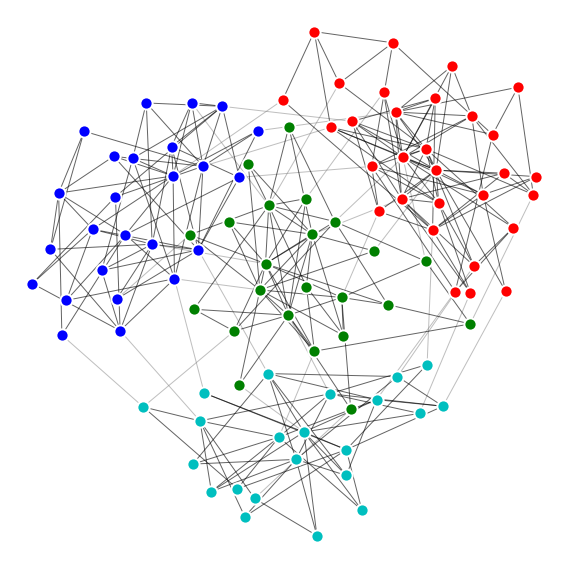

In [91]:
toy_g = nx.read_edgelist('../LFR/toy-network.dat', nodetype=int)
toy_g.name = 'toy'

pos = nx.nx_agraph.graphviz_layout(toy_g, prog='neato')

clusters = {}
with open('../LFR/toy-community.dat') as reader:
    for line in reader:
        u, c_u = map(int, line.split())
        if c_u not in clusters:
            clusters[c_u] = []
        clusters[c_u].append(u)

# g = nx.convert_node_labels_to_integers(g)
ground_truth_clustering = NodeClustering(communities=list(clusters.values()), graph=toy_g)

ax = plot_network_clusters(partition=ground_truth_clustering, graph=toy_g, position=pos, node_size=150)
ax.grid(False)
ax.axis('off');
# plt.savefig('../results/toy.png', bbox_inches='tight', dpi=300)

In [10]:
from src.clustering import CorrelationClustering
from src.utils import Paths, plot_network_clusters

In [7]:
from cdlib import evaluation, algorithms

In [127]:
def plot_clusterings(method, g, ground_truth_clustering=None, cmap='tab20', plot_ground_truth=True, 
                     continuous=True):
    paths = Paths('../')

    corr_cluster = CorrelationClustering(paths=paths, continuous=continuous, exact=True,
                                        input_graph=g, ground_truth_clustering=ground_truth_clustering,
                                        method=method)

    gen_clusters = corr_cluster.run(num_trials=50, overwrite=True, write_stats=False)
    # pick the clusters with either highest NMI and highest EC score 
    best_clusters = {}
    for tau, clustering_trials in gen_clusters.items():
        best_score = 0
        best_clustering = clustering_trials[0]
        for clustering in clustering_trials[1: ]:
            score = clusim_ec_score(ground_truth_clustering, clustering)  
            # score = evaluation.normalized_mutual_information(ground_truth_clustering, clustering)  
            if score > best_score:
                best_score = score
                best_clustering = clustering
        best_clusters[tau] = (best_clustering, best_score)
    
    if ground_truth_clustering is None or not plot_ground_truth:
        ncols = 5
        fig, axs = plt.subplots(nrows=1, ncols=ncols, figsize=(25, 5), layout='tight')
        offset = 0  # for the plots
    else:
        ncols = 6
        fig, axs = plt.subplots(nrows=1, ncols=ncols, figsize=(30, 7.5), layout='tight')        
        plot_network_clusters(partition=ground_truth_clustering, graph=g, position=pos, ax=axs[0])
        axs[0].set_title(f'ground clusters: {len(ground_truth_clustering.communities)}', fontsize=20)    
        axs[0].grid(False)
        axs[0].set_facecolor('lightgray')
        offset = 1



    for i, (tau, gen_clustering_things) in enumerate(best_clusters.items()):
        ax = axs[i+offset]
        gen_clustering, score = gen_clustering_things
        
        tau, tau_max = gen_clustering.method_parameters['tau'], gen_clustering.method_parameters['tau_max']
        frac = tau / tau_max
        nmi = evaluation.normalized_mutual_information(gen_clustering, ground_truth_clustering).score
        # nmi = np.nan
        if ground_truth_clustering is not None:
            title = fr'$\tau_{{f}}$: {frac:.2f} clusters: {len(gen_clustering.communities)} EC: {score:.2f} NMI: {nmi:.2f}'
        
        plot_network_clusters(partition=gen_clustering, graph=g, position=pos, ax=ax, cmap=cmap)
        ax.set_title(title, fontsize=20)
        ax.grid(False)
    
    suptitle = f'{method=!r}-C exact' if continuous else f'{method=!r}-D exact'
    fig.suptitle(suptitle, fontsize=30);
    plt.savefig(f'../results/{method}-C.png', dpi=300, bbox_inches='tight')
    return best_clusters

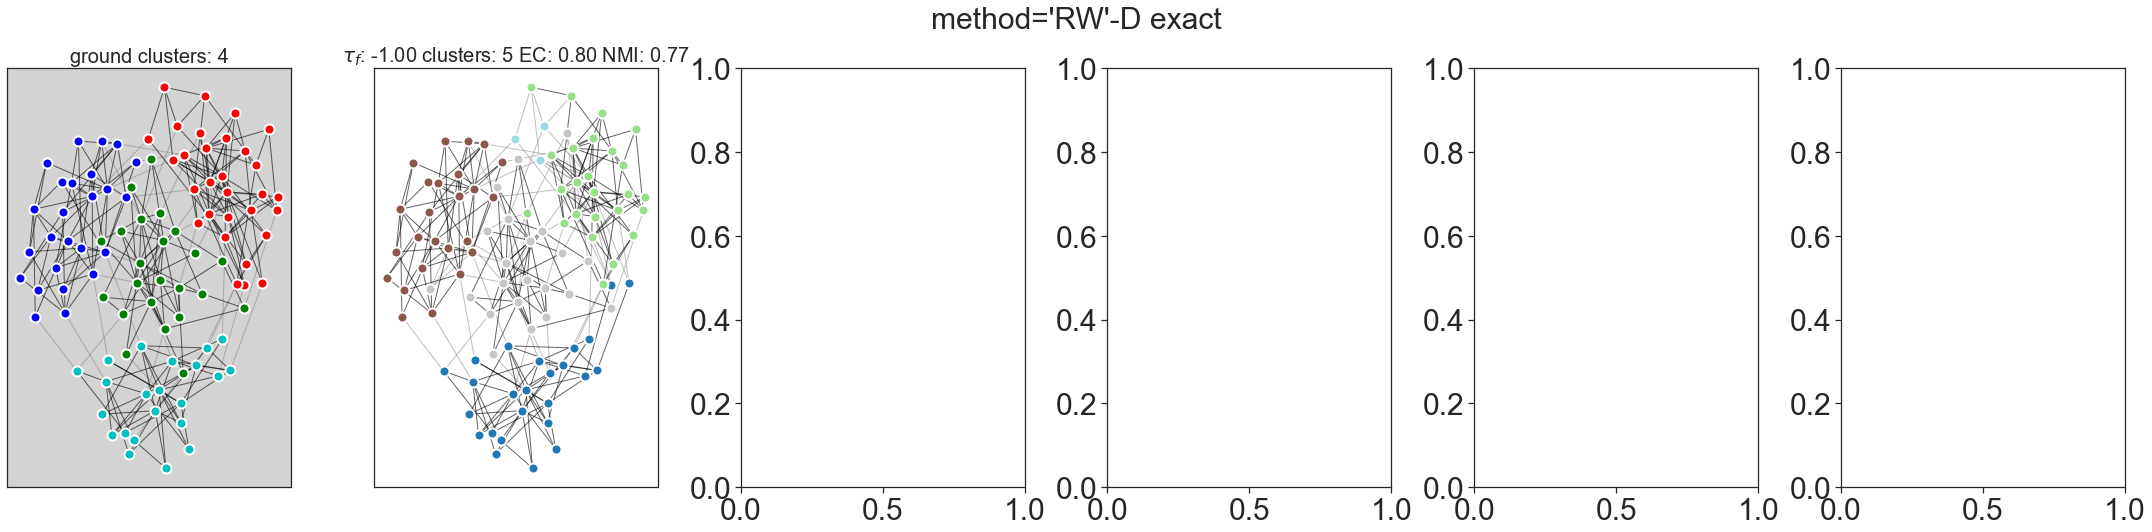

In [137]:
gen_clustering = clusterings[-1][0]
method = 'RW'
continuous = False
clusterings = plot_clusterings(method=method, g=toy_g, continuous=continuous,
                               ground_truth_clustering=ground_truth_clustering)

gen_clustering = clusterings[-1][0]

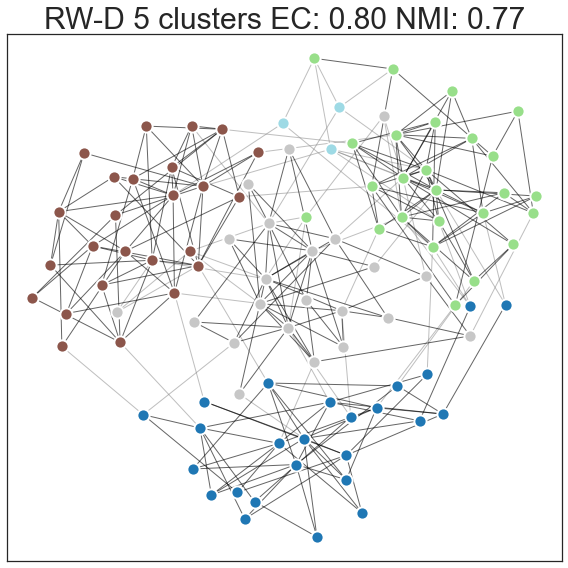

In [138]:
ax = plot_network_clusters(partition=gen_clustering, graph=toy_g, cmap='tab20', node_size=150,
                          position=pos)
nmi = evaluation.normalized_mutual_information(gen_clustering, ground_truth_clustering).score
score = clusim_ec_score(gen_clustering, ground_truth_clustering)

title = fr'{method}-D {len(gen_clustering.communities)} clusters EC: {score:.2f} NMI: {nmi:.2f}'
ax.set_title(title);
plt.savefig(f'../results/{method}-D.png', dpi=300, bbox_inches='tight')

<AxesSubplot:>

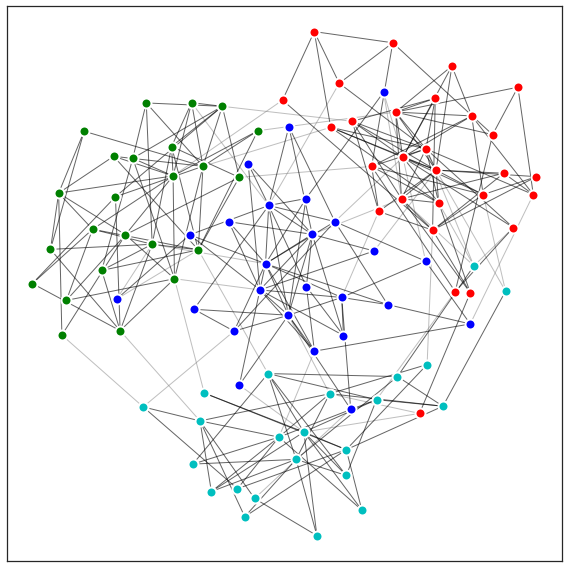

In [74]:
cnm_clusters = algorithms.greedy_modularity(g)
plot_network_clusters(partition=cnm_clusters, graph=g, position=pos)

{0.0: (<cdlib.classes.node_clustering.NodeClustering at 0x1d1f54460>,
  0.8986666666666666),
 0.03277035025962519: (<cdlib.classes.node_clustering.NodeClustering at 0x1d1fc7c70>,
  0.9306666666666665),
 0.06554070051925039: (<cdlib.classes.node_clustering.NodeClustering at 0x1d1f6d0d0>,
  1.0),
 0.09831105077887559: (<cdlib.classes.node_clustering.NodeClustering at 0x1d1f64040>,
  1.0),
 0.13108140103850077: (<cdlib.classes.node_clustering.NodeClustering at 0x1d1f646a0>,
  0.9710512820512821)}

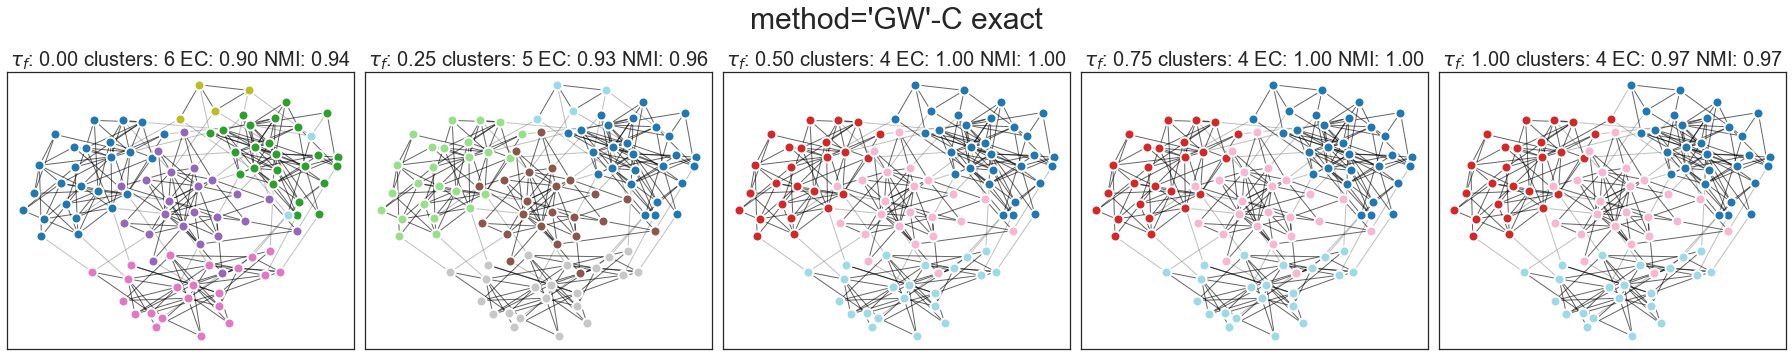

In [128]:
plot_clusterings(method='GW', g=g, ground_truth_clustering=ground_truth_clustering, plot_ground_truth=False)

{0.0: (<cdlib.classes.node_clustering.NodeClustering at 0x1d226d670>,
  0.5268463768115941),
 0.1467164682446688: (<cdlib.classes.node_clustering.NodeClustering at 0x1d22628e0>,
  0.7042666666666669),
 0.2934329364893376: (<cdlib.classes.node_clustering.NodeClustering at 0x1d2249760>,
  0.9306666666666665),
 0.44014940473400643: (<cdlib.classes.node_clustering.NodeClustering at 0x1d225a610>,
  1.0),
 0.5868658729786752: (<cdlib.classes.node_clustering.NodeClustering at 0x1d22d9730>,
  1.0)}

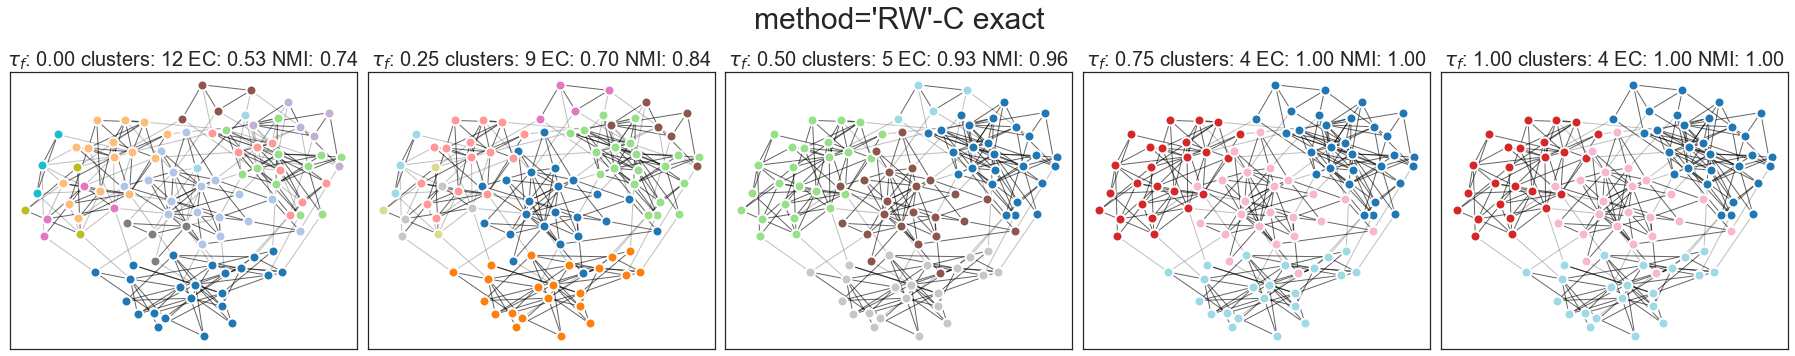

In [129]:
plot_clusterings(method='RW', g=g, ground_truth_clustering=ground_truth_clustering, plot_ground_truth=False)

{0.0: (<cdlib.classes.node_clustering.NodeClustering at 0x1d13f3490>,
  0.8202666666666665),
 0.01597980521198559: (<cdlib.classes.node_clustering.NodeClustering at 0x1d1a16460>,
  0.9306666666666665),
 0.03195961042397118: (<cdlib.classes.node_clustering.NodeClustering at 0x1d1a1bd00>,
  0.9306666666666665),
 0.047939415635956766: (<cdlib.classes.node_clustering.NodeClustering at 0x1d13fd3d0>,
  1.0),
 0.06391922084794235: (<cdlib.classes.node_clustering.NodeClustering at 0x1d17907c0>,
  1.0)}

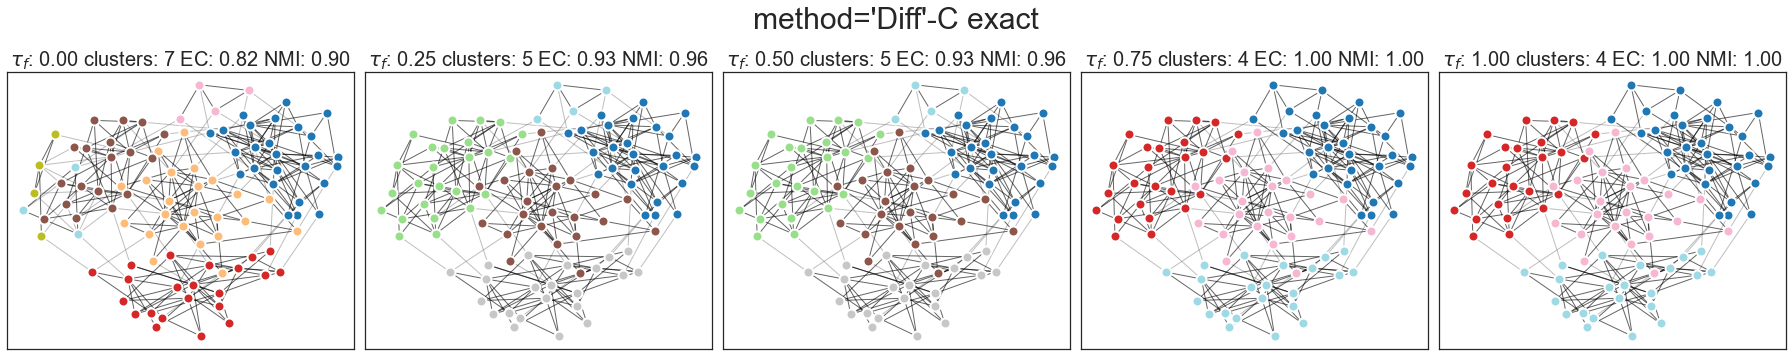

In [130]:
plot_clusterings(method='Diff', g=g, ground_truth_clustering=ground_truth_clustering, plot_ground_truth=False)

In [87]:
# save these toy clusterings for posteriority 


## Resolution limit experiments

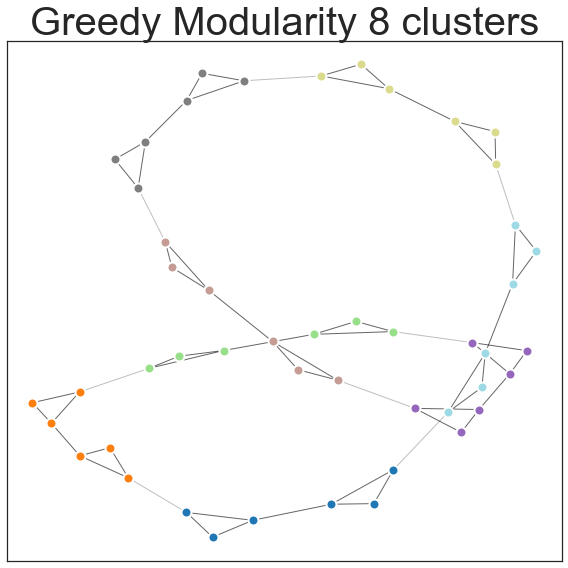

In [40]:
cliq_ring = nx.ring_of_cliques(num_cliques=16, clique_size=3)
cliq_ring.name = 'cliq-ring'
pos = nx.spring_layout(cliq_ring)

# clusters  = algorithms.louvain(cliq_ring, resolution=1)
clusters = algorithms.greedy_modularity(cliq_ring)
# clusters = algorithms.leiden(cliq_ring)
plot_network_clusters(partition=clusters, graph=cliq_ring, cmap='tab20', title=f'{clusters.method_name} {len(clusters.communities)} clusters');

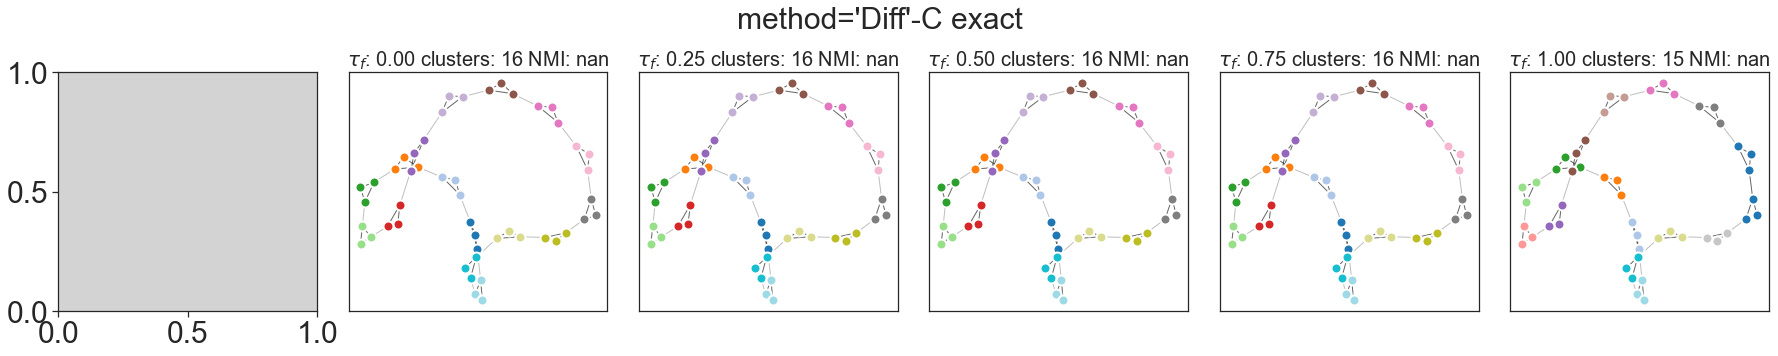

In [41]:
plot_clusterings(method='Diff', g=cliq_ring)

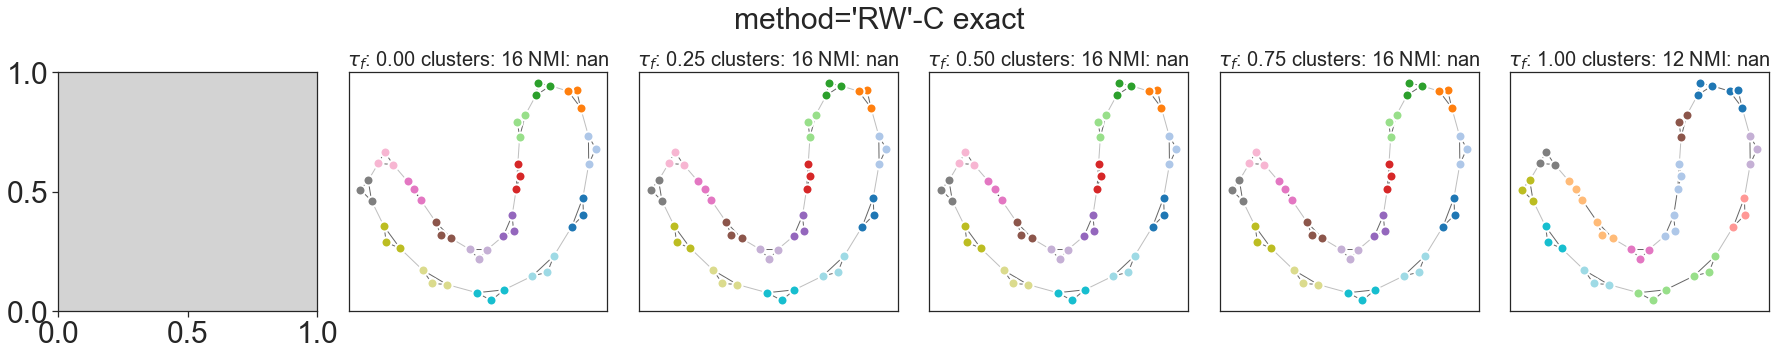

In [38]:
plot_clusterings(method='RW', g=cliq_ring)

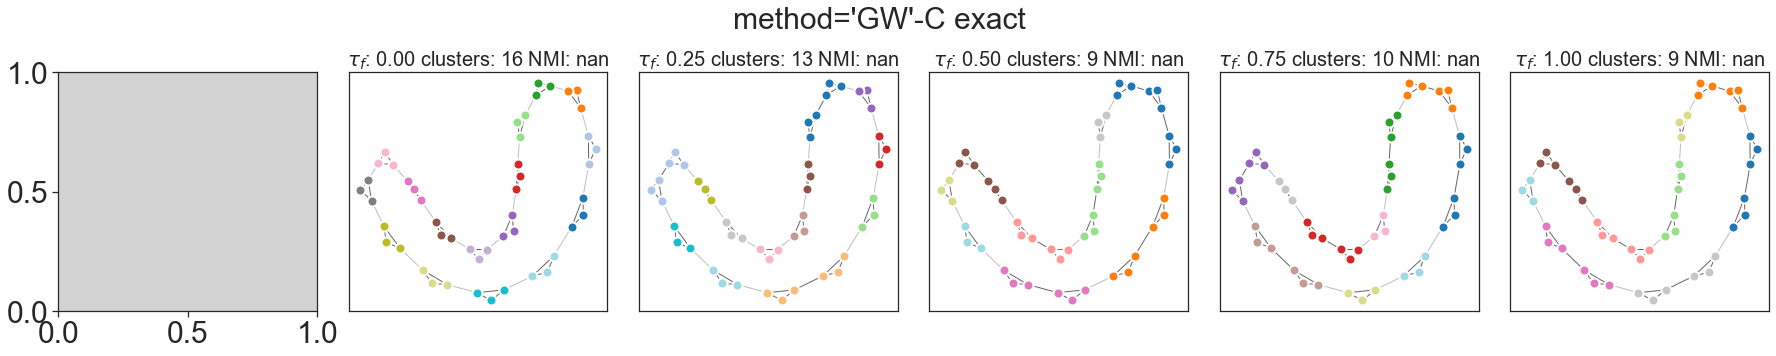

In [39]:
plot_clusterings(method='GW', g=cliq_ring)

## CluSim

In [43]:
from clusim.clustering import Clustering, print_clustering
import clusim.sim as sim

In [51]:
g = nx.karate_club_graph()
comm1 = algorithms.louvain(g)
comm2 = algorithms.greedy_modularity(g)

clu_dict1 = {i: clusters for i, clusters in enumerate(comm1.communities)}
clu_dict2 = {i: clusters for i, clusters in enumerate(comm2.communities)}

In [56]:
clusim_ec_score(comm1, comm2)

0.6398171033119131

In [ ]:
sim.